# REAL-CV-3. Сравнение движений на видео

**Спринт III · Skillfactory · виртуальный коуч**

Сравниваем выбранный фрагмент **`reference_video.mp4`, 00:04–00:09**, с
**`my.mp4`, 00:00–00:05**. Извлекаем позу из каждой пары кадров, выполняем
аффинное совмещение и считаем метрики второго спринта: косинусное сходство
и взвешенное L1-расстояние. Показываем изменение метрик во времени и видео со скелетами.

## Запуск в составе проекта

Это сохранённый учебный этап. Основной пример финальной версии находится в `examples/01_video_comparison.ipynb`.

## 1. Параметры и правила сравнения

- Интервалы полуоткрытые: `[4, 9)` секунд референса и `[0, 5)` секунд входного ролика.
- Сравниваем кадры с одинаковым временем от начала выбранных интервалов.
  Анализируем 24 пары/с; при исходных 30 и 24 кадрах/с это **120 пар**.
  Берём ближайший реальный кадр каждого источника, записываем его индекс и время.
- Скорость видео не меняется, сдвиг по времени не подбирается по лучшей метрике.
  Поэтому запаздывание движений также влияет на результат.
- В каждом кадре выбираем человека с наибольшим score выше 0.9. Для этой пары
  роликов ожидается один основной исполнитель. Число кандидатов сохраняется.
- Сопоставляем одноимённые суставы со score выше 2 на обоих кадрах; необходимо
  не менее 6 общих точек и невырожденная система. Пропуски остаются `NaN`,
  не превращаются в нулевую ошибку и не интерполируются.

`left`/`right` — стороны тела человека. Оценки `keypoints_scores` не являются
вероятностями. Зеркальное переименование суставов не выполняется.

In [1]:
from pathlib import Path
from time import perf_counter
import csv
import hashlib
import json
import platform
import shutil
import subprocess

import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import torch
import torchvision
from PIL import Image, ImageDraw, ImageFont
from IPython.display import Markdown, Video, display
from torchvision import transforms as T
from torchvision.models.detection import (
    KeypointRCNN_ResNet50_FPN_Weights, keypointrcnn_resnet50_fpn,
)

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110, "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 14, "axes.spines.top": False, "axes.spines.right": False,
})
COLORS = {"reference": "#2467C8", "input": "#D46D1F", "neutral": "#6B7280"}

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "REAL_CV_3_Video_Pose_Comparison.ipynb").is_file():
    PROJECT_DIR = PROJECT_DIR / "examples" / "sprints" / "sprint_3"
REFERENCE_PATH = PROJECT_DIR / "reference_video.mp4"
INPUT_PATH = PROJECT_DIR / "my.mp4"
OUTPUT_DIR = PROJECT_DIR / "outputs"
REF_START, REF_END = 4.0, 9.0
MY_START = 0.0
ANALYSIS_FPS = 24.0
CONF_THRESHOLD = 0.9
KEYPOINT_THRESHOLD = 2.0
MIN_COMMON_KEYPOINTS = 6
USE_CACHE = True
CACHE_SCHEMA = "real-cv3-keypoints-v1"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
for path in (REFERENCE_PATH, INPUT_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Не найден {path}. Проверьте PROJECT_DIR.")
OUTPUT_DIR.mkdir(exist_ok=True)

torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
torch.backends.cudnn.benchmark = False
versions = {
    "python": platform.python_version(), "torch": torch.__version__,
    "torchvision": torchvision.__version__, "numpy": np.__version__,
    "opencv": cv2.__version__, "matplotlib": matplotlib.__version__,
}
source_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                 for p in (REFERENCE_PATH, INPUT_PATH)}
print("Версии:", versions)
print("Устройство:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Версии: {'python': '3.11.7', 'torch': '2.5.1+cu121', 'torchvision': '0.20.1+cu121', 'numpy': '2.4.6', 'opencv': '4.11.0', 'matplotlib': '3.11.1'}
Устройство: cuda
GPU: NVIDIA GeForce RTX 4070 Ti


## 2. Чтение видео и временная сетка

Используем `cv2.VideoCapture`. Вместо деления номера кадра
на округлённый FPS строим общую сетку времени. Для этих файлов предполагается
постоянный FPS; ниже проверяем фактические временные метки извлечённых кадров.

In [2]:
def video_metadata(path):
    cap = cv2.VideoCapture(str(path))
    try:
        if not cap.isOpened():
            raise RuntimeError(f"Не удалось открыть видео: {path}")
        fps = float(cap.get(cv2.CAP_PROP_FPS))
        count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if not np.isfinite(fps) or fps <= 0 or count <= 0:
            raise ValueError(f"Некорректные FPS/число кадров: {path.name}")
        return {"file": path.name, "fps": fps, "frame_count": count,
                "duration_s": count / fps,
                "width": int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
                "height": int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))}
    finally:
        cap.release()


reference_meta = video_metadata(REFERENCE_PATH)
input_meta = video_metadata(INPUT_PATH)
duration = REF_END - REF_START
MY_END = MY_START + duration
assert 0 <= REF_START < REF_END <= reference_meta["duration_s"]
assert 0 <= MY_START < MY_END <= input_meta["duration_s"]
assert 0 < ANALYSIS_FPS <= min(reference_meta["fps"], input_meta["fps"])
relative_times = np.arange(0, duration - 1e-9, 1 / ANALYSIS_FPS)
reference_targets = REF_START + relative_times
input_targets = MY_START + relative_times
reference_frame_ids = np.floor(reference_targets * reference_meta["fps"] + 0.5).astype(int)
input_frame_ids = np.floor(input_targets * input_meta["fps"] + 0.5).astype(int)
assert np.all(np.diff(reference_frame_ids) > 0) and np.all(np.diff(input_frame_ids) > 0)
assert reference_frame_ids[-1] < reference_meta["frame_count"]
assert input_frame_ids[-1] < input_meta["frame_count"]
assert np.all(reference_frame_ids / reference_meta["fps"] < REF_END)
assert np.all(input_frame_ids / input_meta["fps"] < MY_END)

rows = ["| Файл | Размер, px | FPS | Кадров | Длительность, с | Интервал, с |",
        "| :--- | :--- | ---: | ---: | ---: | :--- |"]
for meta, start, end in [(reference_meta, REF_START, REF_END), (input_meta, MY_START, MY_END)]:
    rows.append(f"| {meta['file']} | {meta['width']} × {meta['height']} | {meta['fps']:g} | "
                f"{meta['frame_count']} | {meta['duration_s']:.3f} | [{start:g}, {end:g}) |")
display(Markdown("\n".join(rows)))
print(f"Сравнение: {len(relative_times)} пар, шаг {1 / ANALYSIS_FPS:.5f} с")
print(f"Окончание my.mp4 вне интервала: {input_meta['duration_s'] - MY_END:.5f} с")

| Файл | Размер, px | FPS | Кадров | Длительность, с | Интервал, с |
| :--- | :--- | ---: | ---: | ---: | :--- |
| reference_video.mp4 | 406 × 718 | 30 | 638 | 21.267 | [4, 9) |
| my.mp4 | 720 × 1280 | 24 | 121 | 5.042 | [0, 5) |

Сравнение: 120 пар, шаг 0.04167 с
Окончание my.mp4 вне интервала: 0.04167 с


In [3]:
def read_sampled_frames(path, frame_ids, meta):
    frames, timestamps = [], []
    cap = cv2.VideoCapture(str(path))
    wanted = set(frame_ids.tolist())
    try:
        if not cap.isOpened():
            raise RuntimeError(f"Не удалось открыть {path.name}")
        for frame_id in range(int(frame_ids[-1]) + 1):
            ok, frame = cap.read()
            if not ok:
                raise RuntimeError(f"Ошибка декодирования {path.name}, кадр {frame_id}")
            if frame_id in wanted:
                frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
                timestamps.append(cap.get(cv2.CAP_PROP_POS_MSEC) / 1000.0)
    finally:
        cap.release()
    timestamps = np.asarray(timestamps)
    if len(frames) != len(frame_ids):
        raise RuntimeError("Извлечены не все выбранные кадры.")
    if not np.allclose(timestamps, frame_ids / meta["fps"], atol=0.002, rtol=0):
        raise ValueError("Метки кадров не соответствуют постоянному FPS: нужно сопоставление по PTS.")
    return frames, timestamps


reference_frames, reference_times = read_sampled_frames(REFERENCE_PATH, reference_frame_ids, reference_meta)
input_frames, input_times = read_sampled_frames(INPUT_PATH, input_frame_ids, input_meta)
assert np.max(np.abs(reference_times - reference_targets)) <= 0.5 / reference_meta["fps"] + 0.002
assert np.max(np.abs(input_times - input_targets)) <= 0.5 / input_meta["fps"] + 0.002
print(f"Извлечено кадров: {len(reference_frames)} + {len(input_frames)}")
print(f"Максимальное отклонение времени референса от сетки: "
      f"{1000 * np.max(np.abs(reference_times - reference_targets)):.2f} мс")
print(f"Последняя пара: reference {reference_times[-1]:.3f} с / my {input_times[-1]:.3f} с")

Извлечено кадров: 120 + 120
Максимальное отклонение времени референса от сетки: 16.67 мс
Последняя пара: reference 8.967 с / my 4.958 с


## 3. Определение ключевых точек

Используем Keypoint R-CNN с весами COCO_V1, как в предыдущих спринтах.
Координаты остаются в исходном разрешении каждого видео.
Файл кеша содержит SHA-256 исходников, параметры, версии библиотек и индексы кадров:
при несовпадении этих данных инференс выполняется заново.
Отсутствие детекции не останавливает цикл: такой кадр явно помечается пропущенным.

In [4]:
weights = KeypointRCNN_ResNet50_FPN_Weights.COCO_V1
keypoints = list(weights.meta["keypoint_names"])
transform = T.Compose([T.ToTensor()])
cache_config = {
    "schema": CACHE_SCHEMA, "input_sha256": source_hashes, "versions": versions,
    "weights": weights.name, "device": str(DEVICE), "conf_threshold": CONF_THRESHOLD,
    "reference_ids": reference_frame_ids.tolist(), "input_ids": input_frame_ids.tolist(),
}
cache_text = json.dumps(cache_config, sort_keys=True, ensure_ascii=False)
cache_path = OUTPUT_DIR / "pose_predictions.npz"
prediction_arrays = None
if USE_CACHE and cache_path.is_file():
    with np.load(cache_path, allow_pickle=False) as cached:
        if str(cached["config"].item()) == cache_text:
            prediction_arrays = {name: cached[name].copy() for name in cached.files if name != "config"}


def infer_sequence(frames, label, model):
    count = len(frames)
    result = {
        "points": np.full((count, 17, 2), np.nan),
        "point_scores": np.full((count, 17), np.nan),
        "boxes": np.full((count, 4), np.nan),
        "person_scores": np.full(count, np.nan),
        "person_ids": np.full(count, -1, dtype=np.int64),
        "candidate_counts": np.zeros(count, dtype=np.int64),
    }
    for frame_id, frame in enumerate(frames):
        with torch.inference_mode():
            prediction = model([transform(frame).to(DEVICE)])[0]
        prediction = {name: value.detach().cpu().numpy() for name, value in prediction.items()}
        candidates = np.flatnonzero((prediction["labels"] == 1) & (prediction["scores"] > CONF_THRESHOLD))
        result["candidate_counts"][frame_id] = len(candidates)
        if len(candidates):
            person_id = int(candidates[np.argmax(prediction["scores"][candidates])])
            result["person_ids"][frame_id] = person_id
            result["person_scores"][frame_id] = prediction["scores"][person_id]
            result["points"][frame_id] = prediction["keypoints"][person_id, :, :2]
            result["point_scores"][frame_id] = prediction["keypoints_scores"][person_id]
            result["boxes"][frame_id] = prediction["boxes"][person_id]
        if (frame_id + 1) % 30 == 0 or frame_id + 1 == count:
            print(f"{label}: {frame_id + 1}/{count}", flush=True)
    return result


if prediction_arrays is None:
    started = perf_counter()
    model = keypointrcnn_resnet50_fpn(weights=weights, progress=False).to(DEVICE).eval()
    reference_pose = infer_sequence(reference_frames, "Референс", model)
    input_pose = infer_sequence(input_frames, "my.mp4", model)
    prediction_arrays = {f"ref_{name}": value for name, value in reference_pose.items()}
    prediction_arrays.update({f"my_{name}": value for name, value in input_pose.items()})
    np.savez_compressed(cache_path, config=np.asarray(cache_text), **prediction_arrays)
    print(f"Инференс и загрузка модели завершены за {perf_counter() - started:.1f} с")
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
else:
    print("Загружен кеш предсказаний: хеши файлов, настройки и версии совпали.")
    reference_pose = {name[4:]: value for name, value in prediction_arrays.items() if name.startswith("ref_")}
    input_pose = {name[3:]: value for name, value in prediction_arrays.items() if name.startswith("my_")}
for label, pose in [("Референс", reference_pose), ("my.mp4", input_pose)]:
    assert pose["points"].shape == (len(relative_times), 17, 2)
    print(f"{label}: человек найден в {(pose['person_ids'] >= 0).sum()}/{len(relative_times)} кадров; "
          f"кадров с несколькими кандидатами — {(pose['candidate_counts'] > 1).sum()}")

Референс: 30/120


Референс: 60/120


Референс: 90/120


Референс: 120/120


my.mp4: 30/120


my.mp4: 60/120


my.mp4: 90/120


my.mp4: 120/120


Инференс и загрузка модели завершены за 12.1 с
Референс: человек найден в 120/120 кадров; кадров с несколькими кандидатами — 6
my.mp4: человек найден в 120/120 кадров; кадров с несколькими кандидатами — 0


## 4. Аффинное совмещение и метрики второго спринта

Для каждой пары решаем `pad(input) @ A ≈ pad(reference)` методом наименьших
квадратов. Такое преобразование допускает разный масштаб по направлениям,
сдвиг формы и отражение; оно свободнее совмещения Прокруста. Матрица оценивается
по тем же точкам, на которых считается ошибка: это ошибка подгонки, не проверка
на независимых данных.

**Косинусное сходство** — скалярное произведение развёрнутых поз, делённое на
произведение их норм; больше — ближе направления. **Взвешенное L1-расстояние** —
`sum(w_i * (abs(dx_i) + abs(dy_i))) / sum(w_i)`; меньше — ближе координаты.
Как во втором спринте, веса — score точек входного изображения, прошедших общий
порог. L1 измеряется в **пикселях исходного референса 406 × 718**, не в пикселях my.mp4.

Дополнительно считаем центрированный косинус и L1, делённое на фиксированную
медианную высоту рамки человека в референсе. Это помогает оценить влияние
начала координат и масштаба. Ни одна из этих величин не является процентом
правильного выполнения движения.

In [5]:
def pad(points):
    points = np.asarray(points, dtype=np.float64)
    if points.ndim != 2 or points.shape[1] != 2 or not np.isfinite(points).all():
        raise ValueError("Ожидается конечный массив координат формы (N, 2).")
    return np.hstack([points, np.ones((len(points), 1))])


def unpad(points):
    return np.asarray(points)[:, :2]


def fit_affine(input_points, reference_points):
    if np.shape(input_points) != np.shape(reference_points):
        raise ValueError("Наборы должны содержать одинаковое число соответствующих точек.")
    X = pad(input_points)
    Y = pad(reference_points)
    A, residuals, rank, singular_values = np.linalg.lstsq(X, Y, rcond=None)
    if rank < 3:
        raise ValueError("Точки вырождены: аффинное преобразование не определено однозначно.")
    A[np.abs(A) < 1e-10] = 0
    assert np.allclose(A[:, 2], [0, 0, 1], atol=1e-8)
    A[:, 2] = [0, 0, 1]
    return A, int(rank)


def cosine_similarity(pose1, pose2):
    first = np.asarray(pose1, dtype=np.float64).reshape(-1)
    second = np.asarray(pose2, dtype=np.float64).reshape(-1)
    if first.shape != second.shape or first.size == 0:
        raise ValueError("Нужны непустые векторы одинакового размера.")
    if not (np.isfinite(first).all() and np.isfinite(second).all()):
        raise ValueError("Координаты должны быть конечными.")
    denominator = np.linalg.norm(first) * np.linalg.norm(second)
    if denominator <= np.finfo(float).eps:
        raise ValueError("Косинусное сходство не определено для нулевого вектора.")
    return float(np.clip(np.dot(first, second) / denominator, -1, 1))


def weight_distance(pose1, pose2, conf1):
    first = np.asarray(pose1, dtype=np.float64).reshape(-1, 2)
    second = np.asarray(pose2, dtype=np.float64).reshape(-1, 2)
    confidences = np.asarray(conf1, dtype=np.float64)
    if first.shape != second.shape or confidences.shape != (len(first),):
        raise ValueError("Одному суставу должны соответствовать две координаты и один вес.")
    if not all(np.isfinite(x).all() for x in (first, second, confidences)):
        raise ValueError("Входы должны быть конечными.")
    if np.any(confidences < 0) or confidences.sum() <= 0:
        raise ValueError("Веса должны быть неотрицательными с положительной суммой.")
    per_point_l1 = np.abs(first - second).sum(axis=1)
    return float(np.dot(confidences, per_point_l1) / confidences.sum())

In [6]:
def get_limbs_from_keypoints(keypoints):
    limbs = [
        [keypoints.index("right_eye"), keypoints.index("nose")],
        [keypoints.index("right_eye"), keypoints.index("right_ear")],
        [keypoints.index("left_eye"), keypoints.index("nose")],
        [keypoints.index("left_eye"), keypoints.index("left_ear")],
        [keypoints.index("right_shoulder"), keypoints.index("right_elbow")],
        [keypoints.index("right_elbow"), keypoints.index("right_wrist")],
        [keypoints.index("left_shoulder"), keypoints.index("left_elbow")],
        [keypoints.index("left_elbow"), keypoints.index("left_wrist")],
        [keypoints.index("right_hip"), keypoints.index("right_knee")],
        [keypoints.index("right_knee"), keypoints.index("right_ankle")],
        [keypoints.index("left_hip"), keypoints.index("left_knee")],
        [keypoints.index("left_knee"), keypoints.index("left_ankle")],
        [keypoints.index("right_shoulder"), keypoints.index("left_shoulder")],
        [keypoints.index("right_hip"), keypoints.index("left_hip")],
        [keypoints.index("right_shoulder"), keypoints.index("right_hip")],
        [keypoints.index("left_shoulder"), keypoints.index("left_hip")],
    ]
    return limbs

limbs = get_limbs_from_keypoints(keypoints)

In [7]:
pair_count = len(relative_times)
common_masks = np.zeros((pair_count, 17), dtype=bool)
affine_matrices = np.full((pair_count, 3, 3), np.nan)
aligned_input = np.full((pair_count, 17, 2), np.nan)
joint_l2 = np.full((pair_count, 17), np.nan)
reference_heights = reference_pose["boxes"][:, 3] - reference_pose["boxes"][:, 1]
reference_scale = float(np.nanmedian(reference_heights))
if not np.isfinite(reference_scale) or reference_scale <= 0:
    raise ValueError("Нет надёжной оценки масштаба человека в референсе.")
metric_names = ["cosine_similarity", "weighted_l1_px", "centered_cosine", "normalized_l1"]
records = []
for i, time_s in enumerate(relative_times):
    ref_points = reference_pose["points"][i]
    my_points = input_pose["points"][i]
    mask = (
        (reference_pose["point_scores"][i] > KEYPOINT_THRESHOLD)
        & (input_pose["point_scores"][i] > KEYPOINT_THRESHOLD)
        & np.isfinite(ref_points).all(axis=1) & np.isfinite(my_points).all(axis=1)
    )
    common_masks[i] = mask
    row = {
        "pair_index": i, "relative_time_s": float(time_s),
        "reference_time_s": float(reference_times[i]), "input_time_s": float(input_times[i]),
        "reference_frame_id": int(reference_frame_ids[i]), "input_frame_id": int(input_frame_ids[i]),
        "common_keypoints": int(mask.sum()), "status": "ok", "reason": "",
        **{name: np.nan for name in metric_names}, "affine_determinant": np.nan,
        "affine_scale_ratio": np.nan,
    }
    if reference_pose["person_ids"][i] < 0 or input_pose["person_ids"][i] < 0:
        row.update(status="missing_person", reason="Нет человека в одном из кадров")
    elif mask.sum() < MIN_COMMON_KEYPOINTS:
        row.update(status="insufficient_points", reason="Недостаточно общих надёжных точек")
    else:
        try:
            A, _ = fit_affine(my_points[mask], ref_points[mask])
            transformed = unpad(pad(my_points) @ A)
            reference_valid, transformed_valid = ref_points[mask], transformed[mask]
            point_weights = input_pose["point_scores"][i, mask]
            row["cosine_similarity"] = cosine_similarity(reference_valid, transformed_valid)
            row["weighted_l1_px"] = weight_distance(reference_valid, transformed_valid, point_weights)
            row["centered_cosine"] = cosine_similarity(
                reference_valid - reference_valid.mean(axis=0),
                transformed_valid - transformed_valid.mean(axis=0),
            )
            row["normalized_l1"] = row["weighted_l1_px"] / reference_scale
            row["affine_determinant"] = float(np.linalg.det(A[:2, :2]))
            scales = np.linalg.svd(A[:2, :2], compute_uv=False)
            row["affine_scale_ratio"] = float(scales[0] / max(scales[1], np.finfo(float).eps))
            affine_matrices[i] = A
            aligned_input[i] = transformed
            joint_l2[i, mask] = np.linalg.norm(reference_valid - transformed_valid, axis=1)
        except (ValueError, np.linalg.LinAlgError) as error:
            row.update(status="invalid_geometry", reason=str(error))
            row.update({name: np.nan for name in metric_names})
    records.append(row)

valid_mask = np.asarray([row["status"] == "ok" for row in records])
valid_ids = np.flatnonzero(valid_mask)
if not len(valid_ids):
    raise ValueError("Нет пригодных пар кадров: проверьте детекции и пороги.")
metric_values = {name: np.asarray([row[name] for row in records]) for name in metric_names}
summary = {
    name: {"mean": float(np.mean(values[valid_mask])), "median": float(np.median(values[valid_mask])),
           "min": float(np.min(values[valid_mask])), "max": float(np.max(values[valid_mask]))}
    for name, values in metric_values.items()
}
print(f"Пригодных пар: {len(valid_ids)}/{pair_count}; пропущено: {pair_count - len(valid_ids)}")
print(f"Медианная высота рамки эталона: {reference_scale:.1f} px")

Пригодных пар: 120/120; пропущено: 0


Медианная высота рамки эталона: 527.6 px


### Проверки расчётов

Проверяем накопление взвешенной суммы на известном примере, тождественное
совмещение и одну реальную пару независимым циклом. Также проверяем диапазоны,
покрытие и соответствие временной сетке. 

In [8]:
assert np.isclose(cosine_similarity([1, 0], [0, 1]), 0)
assert np.isclose(cosine_similarity([1, 2], [2, 4]), 1)
assert np.isclose(weight_distance([[0, 0], [0, 0]], [[1, 2], [3, 4]], [1, 3]), 6)
assert np.isclose(weight_distance([[0, 0], [0, 0]], [[1, 2], [3, 4]], [10, 30]), 6)
first_id = int(valid_ids[0])
mask = common_masks[first_id]
same_points = reference_pose["points"][first_id, mask]
identity, _ = fit_affine(same_points, same_points)
assert np.allclose(identity, np.eye(3), atol=1e-8)
assert np.isclose(weight_distance(same_points, same_points, np.ones(len(same_points))), 0)
manual_numerator = 0.0
manual_denominator = 0.0
for a, b, weight in zip(same_points, aligned_input[first_id, mask], input_pose["point_scores"][first_id, mask]):
    manual_numerator += weight * (abs(a[0] - b[0]) + abs(a[1] - b[1]))
    manual_denominator += weight
assert np.isclose(manual_numerator / manual_denominator, records[first_id]["weighted_l1_px"])
assert np.all(np.abs(metric_values["cosine_similarity"][valid_mask]) <= 1)
assert np.all(metric_values["weighted_l1_px"][valid_mask] >= 0)
assert np.all(np.isnan(metric_values["weighted_l1_px"][~valid_mask]))
assert len(records) == len(reference_frames) == len(input_frames)
print("Проверки пройдены: метрики, временные интервалы, число пар и обработка пропусков.")

Проверки пройдены: метрики, временные интервалы, число пар и обработка пропусков.


## 5. Результат сравнения движений

Итог — обычное арифметическое среднее **по пригодным парам** равномерной временной
сетки, а не метрика усреднённой позы. Медиана и диапазон показывают изменение
результата внутри выбранных пяти секунд. Последовательные кадры зависимы;
минимум и максимум не являются доверительным интервалом.

In [9]:
labels = {
    "cosine_similarity": "Косинусное сходство · больше — ближе",
    "weighted_l1_px": "Взвешенное L1, px · меньше — ближе",
    "centered_cosine": "Косинусное сходство после центрирования",
    "normalized_l1": "L1 / медианная высота рамки эталона",
}
rows = ["| Метрика | Среднее | Медиана | Минимум | Максимум |",
        "| :--- | ---: | ---: | ---: | ---: |"]
for name in metric_names:
    digits = 3 if name == "weighted_l1_px" else 6
    formatted = [f"{summary[name][stat]:.{digits}f}" for stat in ["mean", "median", "min", "max"]]
    rows.append("| " + labels[name] + " | " + " | ".join(formatted) + " |")
display(Markdown("\n".join(rows)))
display(Markdown(
    f"**Покрытие:** {len(valid_ids)} из {pair_count} пар кадров "
    f"({len(valid_ids) / pair_count:.1%}). Общих надёжных точек на пригодную пару: "
    f"{common_masks[valid_mask].sum(axis=1).min()}–{common_masks[valid_mask].sum(axis=1).max()}."
))

| Метрика | Среднее | Медиана | Минимум | Максимум |
| :--- | ---: | ---: | ---: | ---: |
| Косинусное сходство · больше — ближе | 0.999479 | 0.999794 | 0.993754 | 0.999962 |
| Взвешенное L1, px · меньше — ближе | 8.099 | 6.906 | 3.469 | 32.662 |
| Косинусное сходство после центрирования | 0.997136 | 0.998930 | 0.962516 | 0.999794 |
| L1 / медианная высота рамки эталона | 0.015351 | 0.013090 | 0.006575 | 0.061907 |

**Покрытие:** 120 из 120 пар кадров (100.0%). Общих надёжных точек на пригодную пару: 16–17.

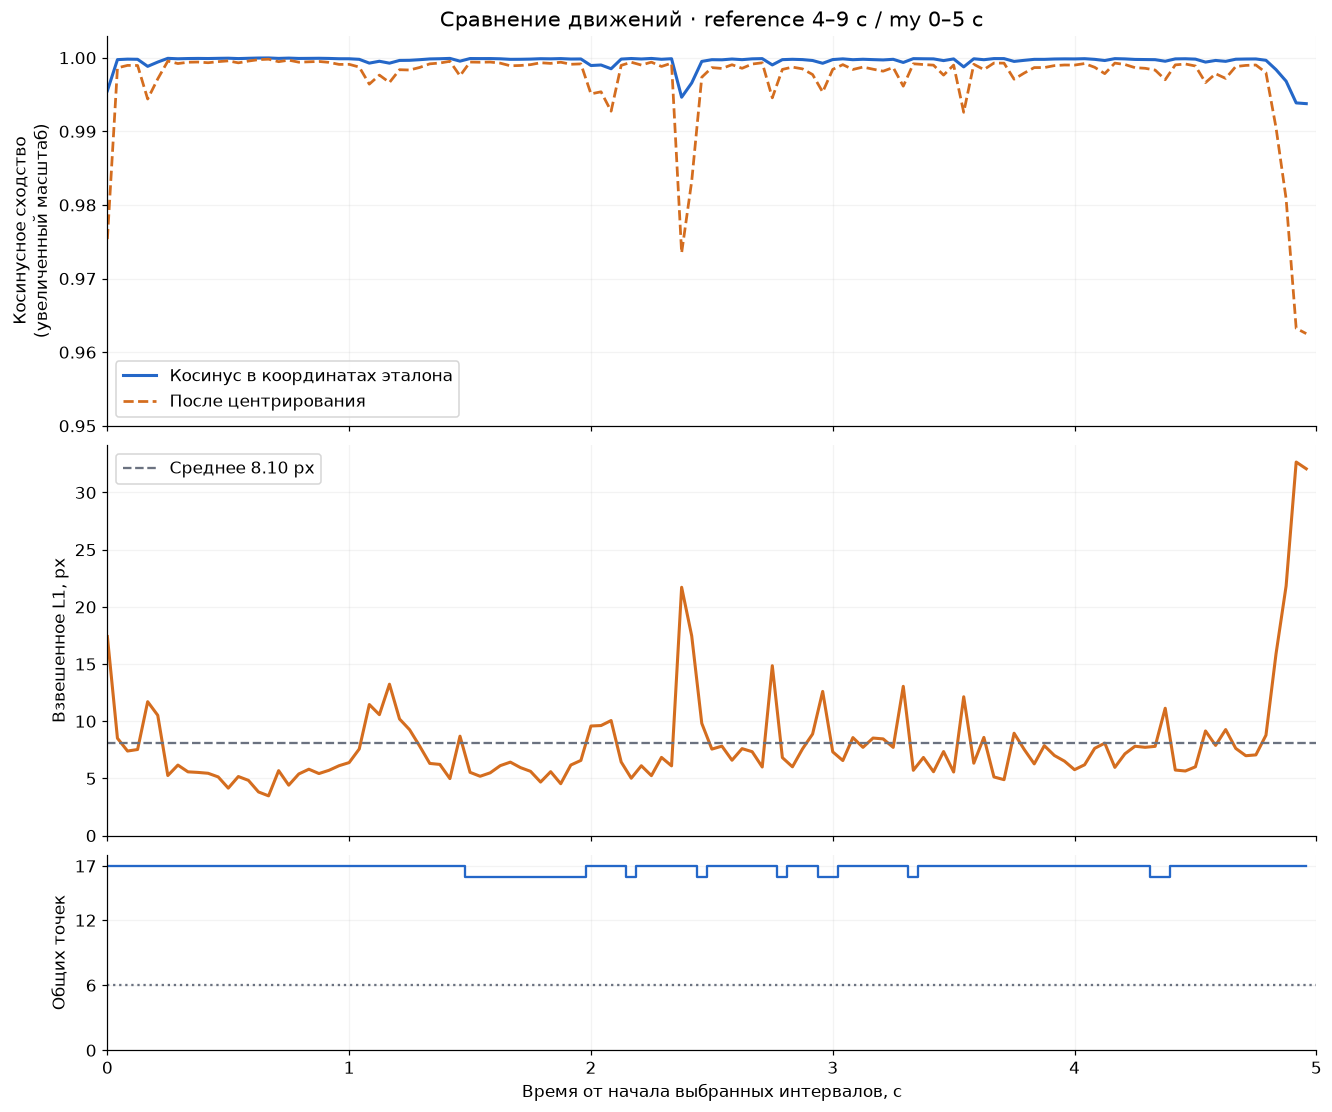

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, constrained_layout=True,
                         gridspec_kw={"height_ratios": [2, 2, 1]})
axes[0].plot(relative_times, metric_values["cosine_similarity"], color=COLORS["reference"],
             linewidth=2, label="Косинус в координатах эталона")
axes[0].plot(relative_times, metric_values["centered_cosine"], color=COLORS["input"],
             linestyle="--", linewidth=1.8, label="После центрирования")
cosine_lower = np.floor(min(np.nanmin(metric_values["cosine_similarity"]),
                            np.nanmin(metric_values["centered_cosine"])) * 20) / 20
axes[0].set_ylim(max(-1, cosine_lower), 1.003)
axes[0].set_ylabel("Косинусное сходство\n(увеличенный масштаб)")
axes[0].set_title(f"Сравнение движений · reference {REF_START:g}–{REF_END:g} с / my {MY_START:g}–{MY_END:g} с")
axes[0].legend(loc="lower left")
axes[1].plot(relative_times, metric_values["weighted_l1_px"], color=COLORS["input"], linewidth=2)
axes[1].axhline(summary["weighted_l1_px"]["mean"], color=COLORS["neutral"], linestyle="--",
                label=f"Среднее {summary['weighted_l1_px']['mean']:.2f} px")
axes[1].set_ylim(bottom=0)
axes[1].set_ylabel("Взвешенное L1, px")
axes[1].legend(loc="upper left")
axes[2].step(relative_times, common_masks.sum(axis=1), where="mid", color=COLORS["reference"])
axes[2].axhline(MIN_COMMON_KEYPOINTS, color=COLORS["neutral"], linestyle=":", label="Минимум для расчёта")
axes[2].set_ylim(0, 18)
axes[2].set_yticks([0, 6, 12, 17])
axes[2].set_ylabel("Общих точек")
axes[2].set_xlabel("Время от начала выбранных интервалов, с")
axes[2].set_xticks(np.arange(0, duration + 1e-6, 1))
axes[2].set_xlim(0, duration)
for ax in axes:
    ax.grid(alpha=0.15)
fig.savefig(OUTPUT_DIR / "metrics_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

### Остаточная ошибка по суставам

Это среднее **евклидово (L2)** отклонение соответствующих точек после совмещения,
а не основная взвешенная L1-метрика. Для каждого сустава показано своё число
пригодных наблюдений `n`. Различия могут быть связаны с движением, ракурсом,
пропорциями и ошибками обнаружения.

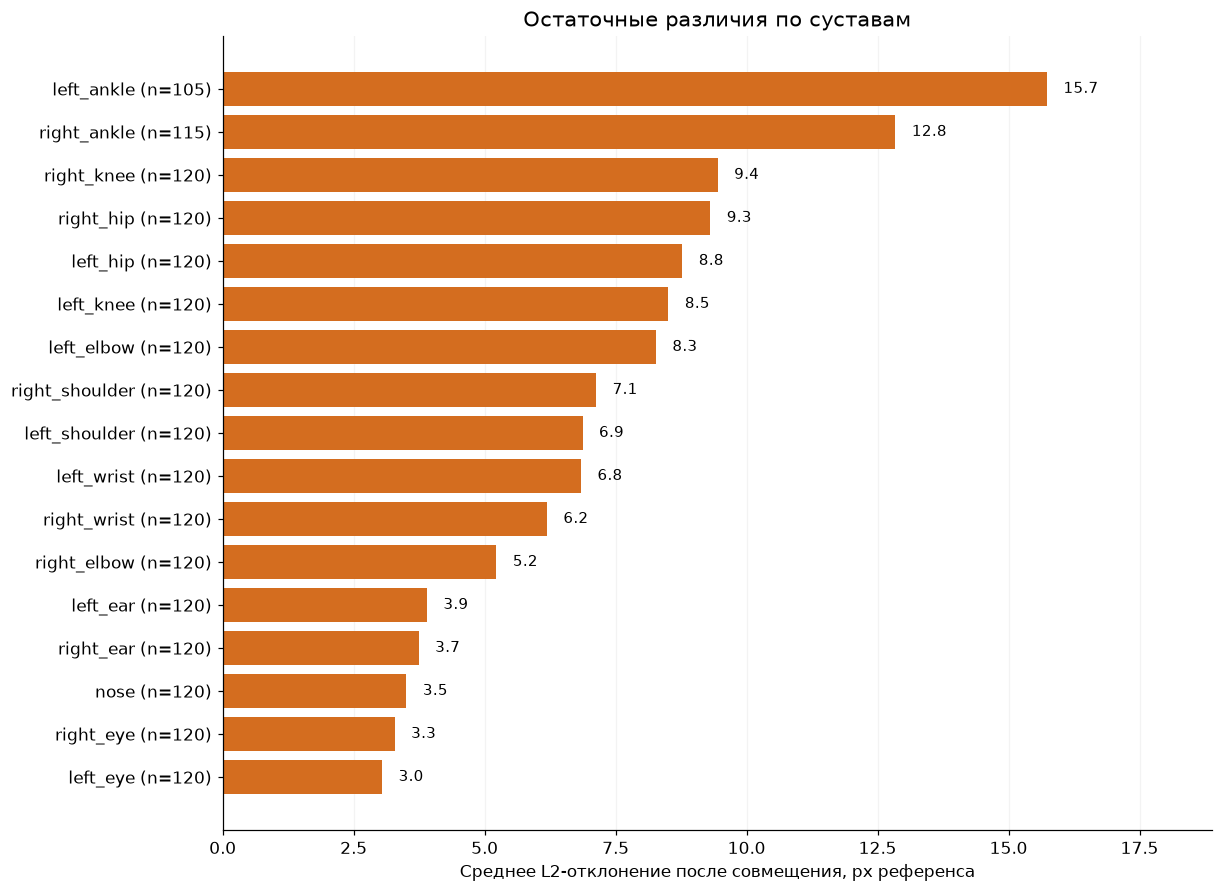

In [11]:
joint_counts = np.isfinite(joint_l2).sum(axis=0)
joint_means = np.divide(np.nansum(joint_l2, axis=0), joint_counts,
                        out=np.full(17, np.nan), where=joint_counts > 0)
joint_order = np.asarray(sorted(np.flatnonzero(joint_counts > 0), key=lambda i: joint_means[i], reverse=True))
fig, ax = plt.subplots(figsize=(11, 8), constrained_layout=True)
joint_labels = [f"{keypoints[i]} (n={joint_counts[i]})" for i in joint_order]
ax.barh(joint_labels, joint_means[joint_order], color=COLORS["input"])
ax.invert_yaxis()
max_error = float(np.max(joint_means[joint_order]))
ax.set_xlim(0, max(1.0, max_error * 1.2))
for rank_id, joint_id in enumerate(joint_order):
    ax.text(joint_means[joint_id] + max_error * 0.02, rank_id,
            f"{joint_means[joint_id]:.1f}", va="center", fontsize=10)
ax.set_xlabel("Среднее L2-отклонение после совмещения, px референса")
ax.set_title("Остаточные различия по суставам")
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
fig.savefig(OUTPUT_DIR / "joint_errors.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Найденные скелеты на кадрах

На фотографиях показаны точки и связи, прошедшие порог **в конкретном кадре**.
Метрики выше используют только пересечение надёжных точек двух кадров.
Скелеты на фотографиях находятся в исходных координатах: преобразование применяется
к координатам для расчёта, а не к самим изображениям.

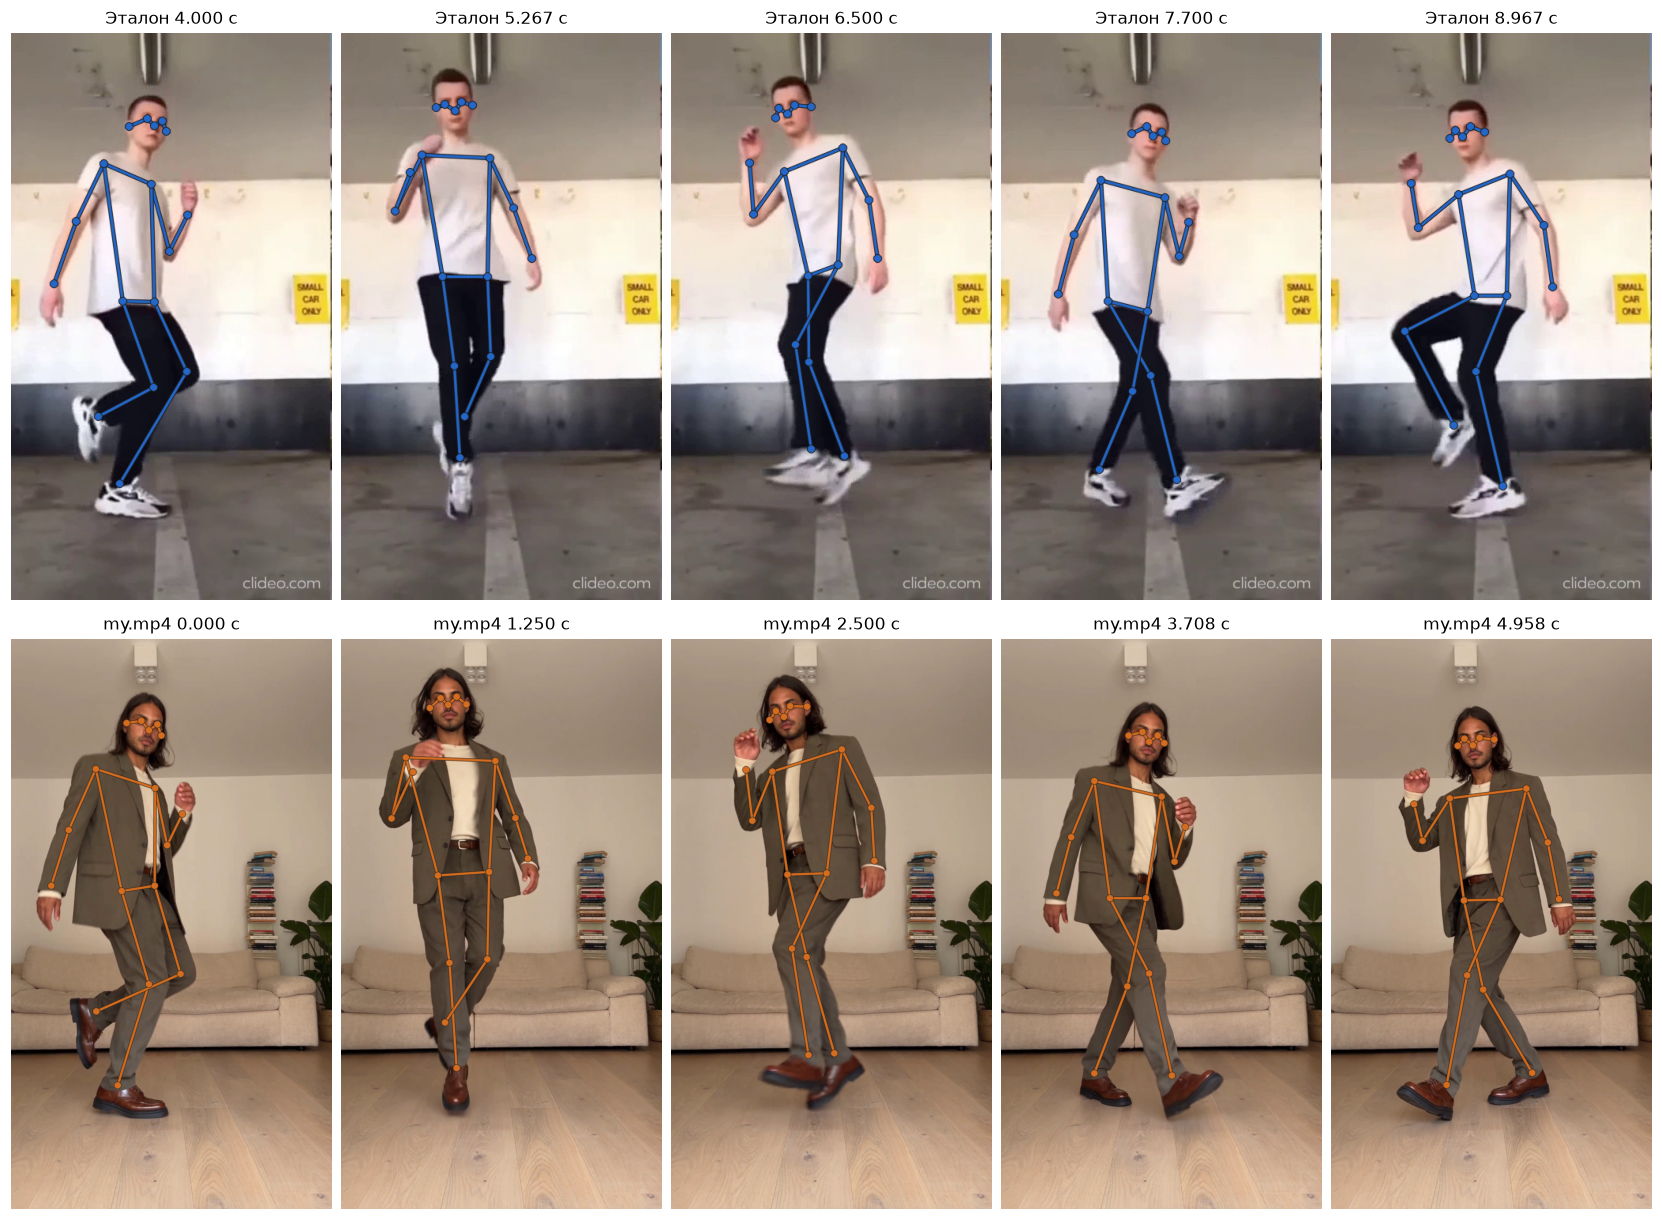

In [12]:
def draw_pose(image, pose, frame_id, color):
    result = image.copy()
    points = pose["points"][frame_id]
    scores = pose["point_scores"][frame_id]
    visible = (scores > KEYPOINT_THRESHOLD) & np.isfinite(points).all(axis=1)
    width = max(2, round(image.shape[0] / 300))
    radius = max(3, round(image.shape[0] / 180))
    for a, b in limbs:
        if visible[a] and visible[b]:
            start, end = [tuple(np.rint(point).astype(int).tolist()) for point in points[[a, b]]]
            cv2.line(result, start, end, (25, 25, 25), width + 2, cv2.LINE_AA)
            cv2.line(result, start, end, color, width, cv2.LINE_AA)
    for point in points[visible]:
        position = tuple(np.rint(point).astype(int).tolist())
        cv2.circle(result, position, radius + 1, (25, 25, 25), -1, cv2.LINE_AA)
        cv2.circle(result, position, radius, color, -1, cv2.LINE_AA)
    return result


reference_color = (36, 103, 200)
input_color = (212, 109, 31)
sample_ids = np.rint(np.linspace(0, pair_count - 1, 5)).astype(int)
fig, axes = plt.subplots(2, len(sample_ids), figsize=(15, 11), constrained_layout=True)
for col, i in enumerate(sample_ids):
    axes[0, col].imshow(draw_pose(reference_frames[i], reference_pose, i, reference_color))
    axes[0, col].set_title(f"Эталон {reference_times[i]:.3f} с", fontsize=11)
    axes[1, col].imshow(draw_pose(input_frames[i], input_pose, i, input_color))
    axes[1, col].set_title(f"my.mp4 {input_times[i]:.3f} с", fontsize=11)
    for row in (0, 1):
        axes[row, col].axis("off")
fig.savefig(OUTPUT_DIR / "sampled_skeletons.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Видео сравнения

Слева — выбранные кадры референса, справа — кадры `my.mp4`. Видео воспроизводится
с частотой анализа 24 кадра/с и длится пять секунд. В верхней части указаны реальные
времена исходных кадров, внизу — метрики текущей пары. Звук не включён: здесь
проверяем движение и позу. MP4 кодируется в H.264 для воспроизведения в ноутбуке.

In [13]:
font_path = font_manager.findfont("DejaVu Sans")
video_font = ImageFont.truetype(font_path, 18)
video_small_font = ImageFont.truetype(font_path, 17)


def make_comparison_frame(i):
    canvas = Image.new("RGB", (720, 768), (248, 250, 252))
    draw = ImageDraw.Draw(canvas)
    for offset, frame, pose, color in [
        (0, reference_frames[i], reference_pose, reference_color),
        (360, input_frames[i], input_pose, input_color),
    ]:
        picture = Image.fromarray(draw_pose(frame, pose, i, color))
        picture.thumbnail((360, 640), Image.Resampling.LANCZOS)
        canvas.paste(picture, (offset + (360 - picture.width) // 2,
                              48 + (640 - picture.height) // 2))
    draw.text((12, 14), f"Эталон · {reference_times[i]:.3f} с", font=video_font, fill=reference_color)
    draw.text((372, 14), f"my.mp4 · {input_times[i]:.3f} с", font=video_font, fill=input_color)
    row = records[i]
    if row["status"] == "ok":
        message = f"Косинус: {row['cosine_similarity']:.5f}   |   L1: {row['weighted_l1_px']:.2f} px"
    else:
        message = f"Метрика пропущена: {row['status']}"
    draw.text((12, 700), message, font=video_font, fill=(25, 35, 50))
    draw.text((12, 733), f"Время фрагмента: {relative_times[i]:.3f} с   |   Общих точек: {row['common_keypoints']}/17",
              font=video_small_font, fill=(60, 65, 75))
    return np.asarray(canvas)


def save_comparison_video(path):
    executable = shutil.which("ffmpeg")
    if executable is None:
        raise RuntimeError("Для MP4 нужен FFmpeg в PATH. Установите его и повторите эту ячейку.")
    temporary = path.with_name(path.stem + "_pending.mp4")
    log_path = OUTPUT_DIR / "ffmpeg_encode.log"
    command = [executable, "-y", "-loglevel", "error", "-f", "rawvideo",
               "-pix_fmt", "rgb24", "-s", "720x768", "-r", str(ANALYSIS_FPS),
               "-i", "pipe:0", "-an", "-c:v", "libx264", "-preset", "fast",
               "-crf", "20", "-pix_fmt", "yuv420p", "-movflags", "+faststart", str(temporary)]
    with log_path.open("wb") as log:
        process = subprocess.Popen(command, stdin=subprocess.PIPE, stdout=subprocess.DEVNULL,
                                   stderr=log, creationflags=getattr(subprocess, "CREATE_NO_WINDOW", 0))
        try:
            for i in range(pair_count):
                process.stdin.write(make_comparison_frame(i).tobytes())
            process.stdin.close()
            return_code = process.wait(timeout=120)
        except Exception:
            process.kill()
            process.wait()
            raise
    if return_code != 0:
        raise RuntimeError(log_path.read_text(encoding="utf-8", errors="replace"))
    check = video_metadata(temporary)
    assert check["frame_count"] == pair_count
    assert np.isclose(check["fps"], ANALYSIS_FPS)
    assert check["width"] == 720 and check["height"] == 768
    temporary.replace(path)
    return check


comparison_video_path = OUTPUT_DIR / "movement_comparison.mp4"
comparison_video_meta = save_comparison_video(comparison_video_path)
print(f"Сохранено: {comparison_video_path.name}; {comparison_video_meta['frame_count']} кадров; "
      f"{comparison_video_meta['duration_s']:.3f} с")
display(Video(str(comparison_video_path), embed=True, width=720,
              html_attributes="controls muted loop playsinline"))

Сохранено: movement_comparison.mp4; 120 кадров; 5.000 с


## 8. Сохранение расчётов

`frame_metrics.csv` содержит все пары, включая пропущенные и их причины.
`joint_summary.csv` — среднюю L2-ошибку и число наблюдений каждого сустава.
`video_pose_comparison.npz` хранит исходные предсказания, маски, времена и матрицы.
`comparison_results.json` содержит метрики, параметры и хеши источников.
Числа сохраняются без округления для последующих спринтов; в таблицах они округлены
только для чтения.

In [14]:
def write_csv(path, rows):
    with path.open("w", encoding="utf-8-sig", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=rows[0].keys())
        writer.writeheader()
        for row in rows:
            writer.writerow({key: "" if isinstance(value, (float, np.floating)) and not np.isfinite(value)
                             else value for key, value in row.items()})


write_csv(OUTPUT_DIR / "frame_metrics.csv", records)
write_csv(OUTPUT_DIR / "joint_summary.csv", [
    {"keypoint": name, "valid_pairs": int(joint_counts[i]), "mean_l2_reference_px": float(joint_means[i])}
    for i, name in enumerate(keypoints)
])
np.savez_compressed(
    OUTPUT_DIR / "video_pose_comparison.npz",
    **prediction_arrays, common_masks=common_masks, valid_mask=valid_mask,
    relative_times=relative_times, reference_times=reference_times, input_times=input_times,
    reference_frame_ids=reference_frame_ids, input_frame_ids=input_frame_ids,
    affine_matrices=affine_matrices, aligned_input=aligned_input, joint_l2=joint_l2,
    keypoint_names=np.asarray(keypoints), limbs=np.asarray(limbs),
)
run_info = {
    "input_sha256": source_hashes, "reference_video": reference_meta, "input_video": input_meta,
    "assignment_files": ["задание.mhtml", "материалы юнита.mhtml"],
    "reference_interval_s": [REF_START, REF_END], "input_interval_s": [MY_START, MY_END],
    "interval_end_exclusive": True, "analysis_fps": ANALYSIS_FPS,
    "temporal_alignment": "same elapsed time; nearest source frame; no shift search or time warp",
    "max_reference_sampling_error_s": float(np.max(np.abs(reference_times - reference_targets))),
    "max_input_sampling_error_s": float(np.max(np.abs(input_times - input_targets))),
    "pair_count": pair_count, "valid_pair_count": int(valid_mask.sum()),
    "conf_threshold": CONF_THRESHOLD, "keypoint_threshold": KEYPOINT_THRESHOLD,
    "min_common_keypoints": MIN_COMMON_KEYPOINTS,
    "model": "keypointrcnn_resnet50_fpn", "weights": weights.name, "weights_url": weights.url,
    "versions": versions, "device": str(DEVICE), "cache_schema": CACHE_SCHEMA,
    "spatial_alignment": "full affine least squares on jointly confident keypoints in each pair",
    "weighted_l1_definition": "sum(input_score * (abs(dx) + abs(dy))) / sum(input_score)",
    "aggregation": "unweighted arithmetic mean over valid, equally spaced frame pairs",
    "reference_scale_median_bbox_height_px": reference_scale, "metrics": summary,
    "reflected_affine_pairs": int(sum(records[i]["affine_determinant"] < 0 for i in valid_ids)),
    "reference_multiple_candidate_frames": int((reference_pose["candidate_counts"] > 1).sum()),
    "input_multiple_candidate_frames": int((input_pose["candidate_counts"] > 1).sum()),
}
(OUTPUT_DIR / "comparison_results.json").write_text(
    json.dumps(run_info, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8",
)
print("Данные, графики и видео сохранены в:", OUTPUT_DIR.relative_to(PROJECT_DIR))

Данные, графики и видео сохранены в: outputs


## Вывод по заданию

Итог ниже автоматически обновляется по результатам запуска. Метрики показывают
совпадение двумерных поз при выбранном временном сопоставлении. Они зависят
от ракурса, пропорций тела, детектора и свободы аффинной подгонки. Без ручной
разметки и проверенной системы порогов не оцениваем движение как «правильное»
или «неправильное» и не переводим косинус в процент качества.

In [15]:
best_id = int(valid_ids[np.argmin(metric_values["weighted_l1_px"][valid_mask])])
worst_id = int(valid_ids[np.argmax(metric_values["weighted_l1_px"][valid_mask])])
top_joints = "; ".join(f"{keypoints[i]} — {joint_means[i]:.1f} px" for i in joint_order[:3])
reflection_count = run_info["reflected_affine_pairs"]
display(Markdown(
    f"Сравнены **{REF_START:g}–{REF_END:g} с reference_video.mp4** и "
    f"**{MY_START:g}–{MY_END:g} с my.mp4**: пригодны **{len(valid_ids)}/{pair_count} пар**.\n\n"
    f"- Среднее косинусное сходство: **{summary['cosine_similarity']['mean']:.6f}**.\n"
    f"- Среднее взвешенное L1-расстояние: **{summary['weighted_l1_px']['mean']:.3f} px** референса.\n"
    f"- Средний косинус после центрирования: **{summary['centered_cosine']['mean']:.6f}**.\n"
    f"- Среднее L1 / медианная высота рамки эталона: **{summary['normalized_l1']['mean']:.6f}**.\n\n"
    f"Минимальная L1-ошибка — **{records[best_id]['weighted_l1_px']:.2f} px** "
    f"при reference {reference_times[best_id]:.3f} с / my {input_times[best_id]:.3f} с; "
    f"максимальная — **{records[worst_id]['weighted_l1_px']:.2f} px** "
    f"при reference {reference_times[worst_id]:.3f} с / my {input_times[worst_id]:.3f} с.\n\n"
    f"Наибольшие средние остаточные L2-отклонения: {top_joints}. "
    f"Пар с отражением в найденной аффинной матрице: {reflection_count}.\n\n"
    "Высокий косинус в исходных координатах следует сопоставлять с центрированным "
    "косинусом, расстоянием и видео: общий сдвиг координат может приближать его к 1. "
    "Мы сравнили последовательность поз, а скорость суставов и задержку исполнения "
    "отдельными метриками здесь не оценивали.\n\n"
    "Требования спринта выполнены: выбранный участок видео обработан покадрово, "
    "движения сопоставлены с повторением, обе метрики рассчитаны и результаты сохранены."
))

Сравнены **4–9 с reference_video.mp4** и **0–5 с my.mp4**: пригодны **120/120 пар**.

- Среднее косинусное сходство: **0.999479**.
- Среднее взвешенное L1-расстояние: **8.099 px** референса.
- Средний косинус после центрирования: **0.997136**.
- Среднее L1 / медианная высота рамки эталона: **0.015351**.

Минимальная L1-ошибка — **3.47 px** при reference 4.667 с / my 0.667 с; максимальная — **32.66 px** при reference 8.933 с / my 4.917 с.

Наибольшие средние остаточные L2-отклонения: left_ankle — 15.7 px; right_ankle — 12.8 px; right_knee — 9.4 px. Пар с отражением в найденной аффинной матрице: 0.

Высокий косинус в исходных координатах следует сопоставлять с центрированным косинусом, расстоянием и видео: общий сдвиг координат может приближать его к 1. Мы сравнили последовательность поз, а скорость суставов и задержку исполнения отдельными метриками здесь не оценивали.

Требования спринта выполнены: выбранный участок видео обработан покадрово, движения сопоставлены с повторением, обе метрики рассчитаны и результаты сохранены.